<a href="https://colab.research.google.com/github/heri-espino/LDS1071-Machine-Learning/blob/main/notebooks/14_Text-classification_TFIDF-vs-CountVectorizer_R3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 7 · Clasificación de textos
### TF-IDF vs. CountVectorizer + Regresión Logística

**Objetivo:** comparar cómo cambia la clasificación cuando representamos los mismos documentos con TF-IDF o con conteos de palabras.

Basado en **Clase 20**, diapositivas 29–44. Se usan las cuatro categorías originales de *20 Newsgroups*. Las explicaciones están en español y los ejemplos de texto en inglés.

## 1. Librerías y datos


> Ejecutar en Google Colab o Jupyter con Internet: la primera carga del dataset puede descargar archivos.

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="tab10")

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

categorias = [
    "sci.space", "rec.sport.baseball", "comp.graphics", "talk.politics.mideast"
]

datos = fetch_20newsgroups(
    subset="train", categories=categorias,
    remove=("headers", "footers", "quotes"),
    shuffle=True, random_state=42
)
documentos = datos.data
etiquetas = datos.target
nombres = datos.target_names

print("Documentos:", len(documentos))
print("Categorías:", nombres)

Documentos: 2338
Categorías: ['comp.graphics', 'rec.sport.baseball', 'sci.space', 'talk.politics.mideast']


In [25]:
i = 11
print("Categoría:", nombres[etiquetas[i]])
print("Texto:\n", documentos[i][:500])

Categoría: rec.sport.baseball
Texto:
 




I'm not sure I understand this question. When the IF rule is invoked,
the batter is automatically out. This relieves the runners from being
forced to advance to the next base if the ball is not caught. Other
than that, isn't it just the same as any situation in which a runner on
a base is not forced to the next base on a dropped fly ball? That is,
if the ball is caught he can tag up and run (or decide to stay), and
if the ball is dropped he can have left the base at any time.



## 2. Entrenamiento y prueba

Usamos **80 %** de los documentos para entrenar y **20 %** para evaluar. `stratify` conserva aproximadamente la proporción de cada categoría.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    documentos, etiquetas,
    test_size=0.2, random_state=42, stratify=etiquetas
)
print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))

Entrenamiento: 1870
Prueba: 468


## 3. Dos pipelines: TF-IDF y CountVectorizer

- **TF-IDF:** pondera palabras según frecuencia y rareza; además normaliza con L2.
- **CountVectorizer:** cuenta apariciones. **No** utiliza `norm="l2"`, pues ese parámetro no existe en `CountVectorizer`.

El clasificador y sus hiperparámetros se mantienen iguales para que la comparación se concentre en la representación, se usan clases balanceadas.

In [27]:
parametros = dict(
    stop_words="english",
    min_df=5,
    max_df=0.8,
    max_features=5000
)

modelo_tfidf = Pipeline([
    ("vectorizador", TfidfVectorizer(**parametros, norm="l2")),
    ("clasificador", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

modelo_count = Pipeline([
    ("vectorizador", CountVectorizer(**parametros)),
    ("clasificador", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

modelos = {"TF-IDF": modelo_tfidf, "CountVectorizer": modelo_count}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(nombre, "→ vocabulario:", len(modelo.named_steps["vectorizador"].get_feature_names_out()))

TF-IDF → vocabulario: 5000
CountVectorizer → vocabulario: 5000


## 4. Evaluación en los mismos documentos

- **Accuracy:** proporción de aciertos.
- **Precision:** aciertos entre los predichos en una clase.
- **Recall:** aciertos entre los verdaderos de una clase.
- **F1:** media armónica de precision y recall.

In [28]:
predicciones = {}
resultados = []

for nombre, modelo in modelos.items():
    pred = modelo.predict(X_test)
    predicciones[nombre] = pred
    acc = accuracy_score(y_test, pred)
    resultados.append({"Representación": nombre, "Accuracy": acc})
    print(f"\n{nombre} — Accuracy: {acc:.3f}")
    print(classification_report(y_test, pred, target_names=nombres))

tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados.style.format({"Accuracy": "{:.3f}"}))


TF-IDF — Accuracy: 0.868
                       precision    recall  f1-score   support

        comp.graphics       0.88      0.85      0.87       117
   rec.sport.baseball       0.79      0.92      0.85       119
            sci.space       0.88      0.82      0.85       119
talk.politics.mideast       0.93      0.88      0.90       113

             accuracy                           0.87       468
            macro avg       0.87      0.87      0.87       468
         weighted avg       0.87      0.87      0.87       468


CountVectorizer — Accuracy: 0.825
                       precision    recall  f1-score   support

        comp.graphics       0.89      0.79      0.84       117
   rec.sport.baseball       0.73      0.93      0.82       119
            sci.space       0.81      0.78      0.79       119
talk.politics.mideast       0.94      0.79      0.86       113

             accuracy                           0.82       468
            macro avg       0.84      0.82      0.83

,Representación,Accuracy
0,TF-IDF,0.868
1,CountVectorizer,0.825


### Interpretación de la evaluación

En **468 documentos de prueba**, TF-IDF clasificó correctamente **406 (accuracy = 0.868)**, frente a **385 (accuracy = 0.825)** con CountVectorizer: **21 aciertos más**, una diferencia de **4.5 puntos porcentuales**.

**TF-IDF obtuvo un F1 mayor en las cuatro categorías:** gráficos (0.87 frente a 0.84), béisbol (0.85 frente a 0.82), espacio (0.85 frente a 0.79) y política de Medio Oriente (0.90 frente a 0.86).

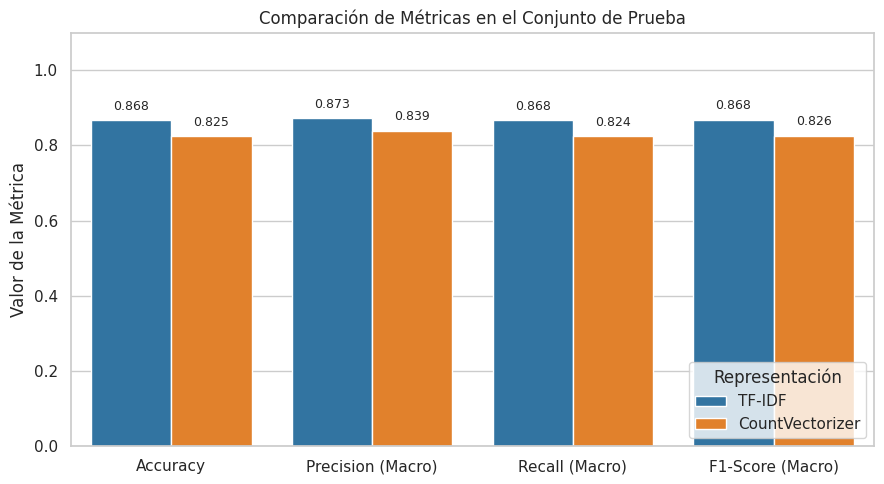

In [29]:
# Gráfico comparativo de todas las métricas con estilo Seaborn whitegrid.
from sklearn.metrics import precision_recall_fscore_support

# Extraemos las métricas promedio para cada modelo
filas_metricas = []
for nombre, modelo in modelos.items():
    pred = predicciones[nombre]
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, pred, average="macro")
    acc = accuracy_score(y_test, pred)

    filas_metricas.extend([
        {"Representación": nombre, "Métrica": "Accuracy", "Valor": acc},
        {"Representación": nombre, "Métrica": "Precision (Macro)", "Valor": precision},
        {"Representación": nombre, "Métrica": "Recall (Macro)", "Valor": recall},
        {"Representación": nombre, "Métrica": "F1-Score (Macro)", "Valor": f1}
    ])

tabla_metricas = pd.DataFrame(filas_metricas)

# Creamos el gráfico comparativo
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=tabla_metricas, x="Métrica", y="Valor",
            hue="Representación", palette="tab10", ax=ax)

# Añadimos los valores sobre cada barra
for p in ax.patches:
    valor = p.get_height()
    if valor > 0:
        ax.text(p.get_x() + p.get_width() / 2, valor + 0.02, f"{valor:.3f}",
                ha="center", va="bottom", fontsize=9)

ax.set(ylim=(0, 1.1), ylabel="Valor de la Métrica", xlabel="",
       title="Comparación de Métricas en el Conjunto de Prueba")
ax.legend(title="Representación", loc="lower right")
fig.tight_layout()
plt.show()

### Matrices de confusión


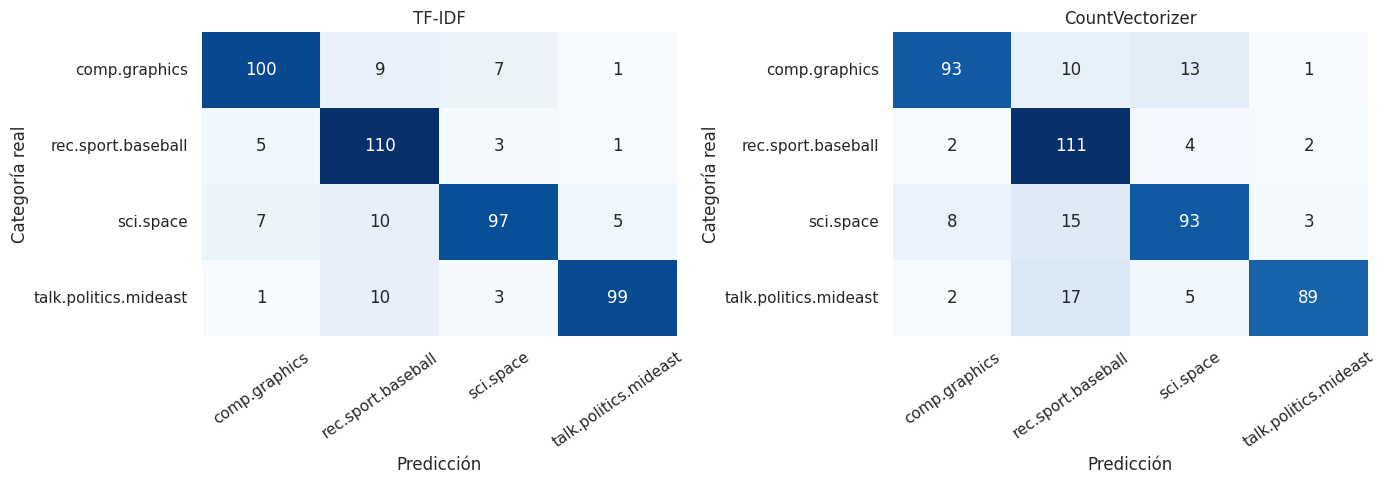

In [30]:
# Dos matrices de confusión en formato heatmap.
from sklearn.metrics import confusion_matrix

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (nombre, pred) in zip(ejes, predicciones.items()):
    matriz = confusion_matrix(y_test, pred, labels=np.arange(len(nombres)))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=nombres, yticklabels=nombres, ax=ax)
    ax.set(title=nombre, xlabel="Predicción", ylabel="Categoría real")
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()

### Interpretación de las matrices de confusión

Béisbol tiene el mayor recall, pero una precisión más baja porque se predicen muchos textos de béisbol, aunque otros documentos también reciben esa etiqueta. El menor rendimiento de CountVectorizer aparece en todas las categorías.


## 5. Examinar aciertos y errores

Mostramos ejemplos de ambos modelos. Los errores ayudan a detectar textos ambiguos, demasiado cortos o con vocabulario compartido.

In [31]:
def mostrar_ejemplos(nombre, aciertos=True, cantidad=3):
    pred = predicciones[nombre]
    indices = np.where(pred == y_test if aciertos else pred != y_test)[0]
    print(f"{nombre}: {len(indices)} {'aciertos' if aciertos else 'errores'}")
    for i in indices[:cantidad]:
        print("\n---")
        print("Real:", nombres[y_test[i]])
        print("Predicción:", nombres[pred[i]])
        print(X_test[i][:350].replace("\n", " "))

for nombre in modelos:
    mostrar_ejemplos(nombre, aciertos=True, cantidad=2)
    mostrar_ejemplos(nombre, aciertos=False, cantidad=2)

TF-IDF: 406 aciertos

---
Real: sci.space
Predicción: sci.space
 A cash award is OK. A time limit would be nice. You can't give away mining rights (assuming there's anything to mine) because you don't own them.  -----------------------------------------------------------------  .sig files are like strings ... every yo-yo's got one.

---
Real: comp.graphics
Predicción: comp.graphics
Howdy all,  	I was wondering if people could e-mail me their opinions on the various graphics viewers available for MS-Windows 3.x...  I'm working on a project to set up our scanner and write documentation on how to use it and it would be nice to have a snazzy image viewer  to look at (and maybe even edit?) the image you just scanned.  The file for
TF-IDF: 62 errores

---
Real: talk.politics.mideast
Predicción: rec.sport.baseball
You a good case for rights to abortion.

---
Real: sci.space
Predicción: talk.politics.mideast
Sounds similar to something Wally Schirra said.
CountVectorizer: 386 aciertos

---
Rea

### Interpretación de los ejemplos

Ambos clasifican incorrectamente ejemplos muy breves, como la frase sobre *abortion* asignada a béisbol, o la referencia a *Wally Schirra* asignada a política en lugar de espacio. Los textos cortos o ambiguos pueden contener pocas señales temáticas útiles; estos ejemplos ilustran errores particulares, no explican todos los fallos.


## 6. Coeficientes: palabras más influyentes

En una clasificación con cuatro categorías, cada clase tiene su propia fila de coeficientes. Un peso **positivo** favorece esa categoría frente a las demás; uno **negativo** la desfavorece. Comparamos los diez extremos de cada fila.

In [32]:
def palabras_influyentes(modelo, cantidad=10):
    terminos = modelo.named_steps["vectorizador"].get_feature_names_out()
    clf = modelo.named_steps["clasificador"]
    filas = []
    for fila, clase in enumerate(clf.classes_):
        pesos = clf.coef_[fila]
        positivos = np.argsort(pesos)[-cantidad:][::-1]
        negativos = np.argsort(pesos)[:cantidad]
        filas.append({
            "Categoría": nombres[clase],
            "Positivas (+)": ", ".join(terminos[positivos]),
            "Negativas (−)": ", ".join(terminos[negativos])
        })
    return pd.DataFrame(filas)

for nombre, modelo in modelos.items():
    print("\n", nombre)
    display(palabras_influyentes(modelo))


 TF-IDF


,Categoría,Positivas (+),Negativas (−)
0,comp.graphics,"graphics, image, file, hi, computer, 3d, files...","space, people, israel, year, baseball, jewish,..."
1,rec.sport.baseball,"baseball, game, year, team, games, players, st...","space, israel, graphics, software, israeli, pr..."
2,sci.space,"space, nasa, orbit, launch, moon, shuttle, ear...","graphics, israel, jewish, israeli, file, baseb..."
3,talk.politics.mideast,"israel, israeli, jews, people, turkish, armeni...","space, thanks, year, graphics, baseball, nasa,..."



 CountVectorizer


,Categoría,Positivas (+),Negativas (−)
0,comp.graphics,"graphics, hi, image, file, looking, ve, comput...","people, space, appreciate, idea, moon, jewish,..."
1,rec.sport.baseball,"baseball, stadium, team, game, writes, games, ...","space, try, israel, real, loser, message, grap..."
2,sci.space,"space, orbit, launch, nasa, moon, things, appr...","graphics, jewish, point, ve, israel, agree, co..."
3,talk.politics.mideast,"israel, loser, israeli, jews, serdar, turkish,...","got, thanks, space, lot, good, actually, looki..."


### Interpretación de los coeficientes

Los dos modelos identifican pistas temáticas similares: *graphics, image, file* para gráficos; *baseball, game, team* para béisbol; *space, nasa, orbit* para espacio; e *israel, israeli, jews* para política de Medio Oriente. Algunas palabras comunes o nombres propios también reciben pesos elevados.

Un coeficiente positivo favorece una clase **en relación con las otras clases**, y uno negativo la desfavorece. No conviene comparar directamente la magnitud de coeficientes entre TF-IDF y conteos, porque cambia la escala de entrada.


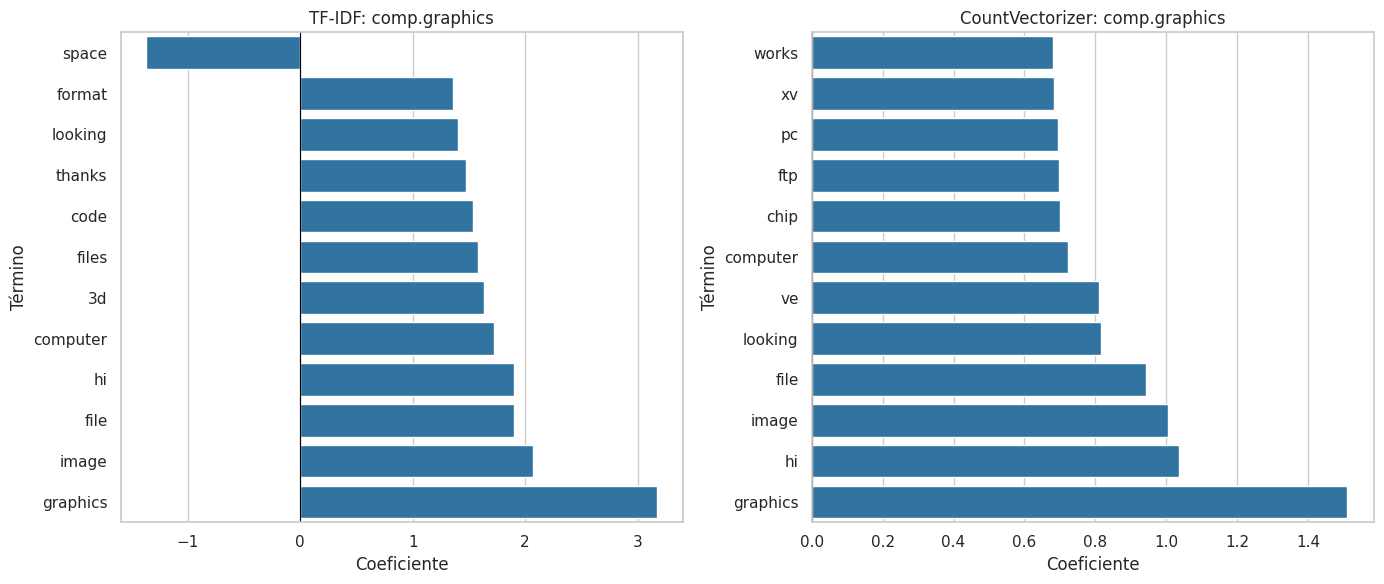

In [33]:
# Coeficientes con Seaborn. Solo la primera clase para evitar saturación.
fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (nombre, modelo) in zip(ejes, modelos.items()):
    terminos = modelo.named_steps["vectorizador"].get_feature_names_out()
    clasificador = modelo.named_steps["clasificador"]
    pesos = clasificador.coef_[0]
    indices = np.argsort(np.abs(pesos))[-12:]
    tabla_pesos = pd.DataFrame({
        "Término": terminos[indices], "Coeficiente": pesos[indices]
    }).sort_values("Coeficiente")
    sns.barplot(data=tabla_pesos, x="Coeficiente", y="Término",
                color=sns.color_palette("tab10")[0], ax=ax)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{nombre}: {nombres[clasificador.classes_[0]]}")
fig.tight_layout()
plt.show()

## 7. Una noticia real en inglés

**Noticia:** “Brewers sweep the Dodgers in the NLCS to reach the World Series for the first time since 1982”  
**Fuente:** Associated Press (Beth Harris), **15 de octubre de 2026**.  
**Enlace:** https://apnews.com/article/brewers-dodgers-score-nlcs-cfd30befcec42a035cbea5cae3bf746c


In [34]:
titulo_noticia = "Brewers sweep the Dodgers in the NLCS to reach the World Series for the first time since 1982"
url_noticia = "https://apnews.com/article/brewers-dodgers-score-nlcs-cfd30befcec42a035cbea5cae3bf746c"

noticia = """
The Milwaukee Brewers advanced to the World Series after defeating the Los Angeles
Dodgers in four games of the National League Championship Series. In the final
baseball game, Milwaukee won 6-4 after overcoming an early Dodgers lead.
Garrett Mitchell hit a go-ahead home run in the sixth inning, while the Brewers'
bullpen and relief pitchers protected the lead. Shohei Ohtani homered for Los
Angeles, but Milwaukee completed the playoff sweep. The Brewers finished the
regular season with 103 victories and will return to the World Series for the
first time since 1982. Baseball fans celebrated the National League pennant.
""".strip()

print(titulo_noticia)
print(url_noticia)
print("\nTexto analizado (resumen original):\n", noticia)

Brewers sweep the Dodgers in the NLCS to reach the World Series for the first time since 1982
https://apnews.com/article/brewers-dodgers-score-nlcs-cfd30befcec42a035cbea5cae3bf746c

Texto analizado (resumen original):
 The Milwaukee Brewers advanced to the World Series after defeating the Los Angeles
Dodgers in four games of the National League Championship Series. In the final
baseball game, Milwaukee won 6-4 after overcoming an early Dodgers lead.
Garrett Mitchell hit a go-ahead home run in the sixth inning, while the Brewers'
bullpen and relief pitchers protected the lead. Shohei Ohtani homered for Los
Angeles, but Milwaukee completed the playoff sweep. The Brewers finished the
regular season with 103 victories and will return to the World Series for the
first time since 1982. Baseball fans celebrated the National League pennant.


### Clasificación y probabilidades

Ambos modelos ven **exactamente el mismo texto**. `predict_proba` estima la distribución entre las cuatro categorías posibles; son probabilidades del modelo, no garantías de corrección.

In [35]:
filas = []
for nombre, modelo in modelos.items():
    etiqueta = modelo.predict([noticia])[0]
    clf = modelo.named_steps["clasificador"]
    probabilidades = modelo.predict_proba([noticia])[0]
    print(f"{nombre} → categoría predicha: {nombres[etiqueta]}")
    for clase, prob in zip(clf.classes_, probabilidades):
        filas.append({"Representación": nombre, "Categoría": nombres[clase], "Probabilidad": prob})

tabla_noticia = pd.DataFrame(filas)
display(tabla_noticia.pivot(index="Categoría", columns="Representación", values="Probabilidad").round(3))

TF-IDF → categoría predicha: rec.sport.baseball
CountVectorizer → categoría predicha: rec.sport.baseball


Representación,CountVectorizer,TF-IDF
Categoría,,
comp.graphics,0.0,0.030
rec.sport.baseball,1.0,0.897
sci.space,0.0,0.036
talk.politics.mideast,0.0,0.037


### Interpretación de la noticia

Ambos modelos asignan la noticia a **rec.sport.baseball**, su tema esperado. TF-IDF da una probabilidad aproximada de **0.897**, mientras que CountVectorizer produce un valor que **redondea a 1.000**.


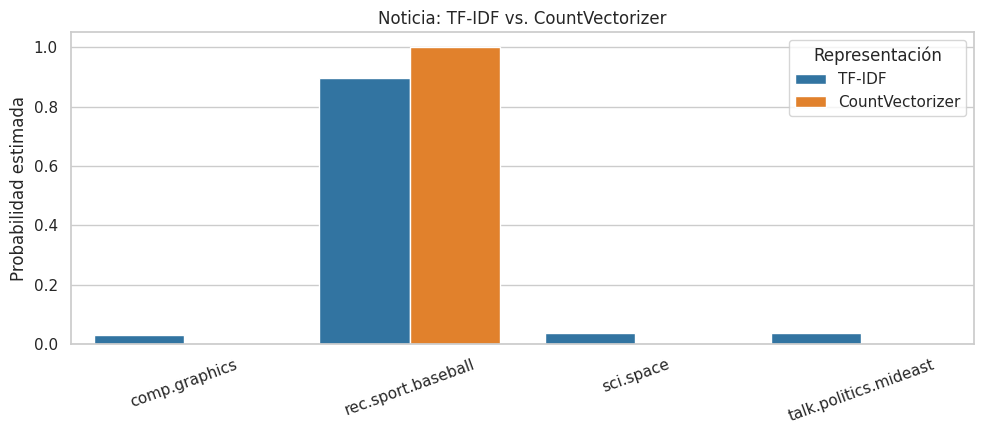

In [36]:
# Probabilidades de clasificación del mismo artículo.
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=tabla_noticia, x="Categoría", y="Probabilidad",
            hue="Representación", order=nombres, ax=ax)
ax.set(ylim=(0, 1.05), ylabel="Probabilidad estimada", xlabel="",
       title="Noticia: TF-IDF vs. CountVectorizer")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()

## 8. Discusión y conclusión


In [37]:
acc_tfidf = tabla_resultados.loc[tabla_resultados["Representación"] == "TF-IDF", "Accuracy"].iloc[0]
acc_count = tabla_resultados.loc[tabla_resultados["Representación"] == "CountVectorizer", "Accuracy"].iloc[0]

ganador = "TF-IDF" if acc_tfidf > acc_count else "CountVectorizer" if acc_count > acc_tfidf else "Empate"
print(f"Accuracy TF-IDF:        {acc_tfidf:.3f}")
print(f"Accuracy CountVectorizer: {acc_count:.3f}")
print("Mejor accuracy:", ganador)
print("Diferencia absoluta:", f"{abs(acc_tfidf - acc_count):.3f}")

for nombre, modelo in modelos.items():
    etiqueta = modelo.predict([noticia])[0]
    prob = modelo.predict_proba([noticia]).max()
    print(f"Noticia ({nombre}): {nombres[etiqueta]} — {prob:.3f}")

Accuracy TF-IDF:        0.868
Accuracy CountVectorizer: 0.825
Mejor accuracy: TF-IDF
Diferencia absoluta: 0.043
Noticia (TF-IDF): rec.sport.baseball — 0.897
Noticia (CountVectorizer): rec.sport.baseball — 1.000




**TF-IDF funcionó mejor en esta práctica:** obtuvo mayor accuracy y F1 en todas las clases. Su ponderación reduce el protagonismo de términos frecuentes y la normalización elimina la influencia de la longitud de los documentos. CountVectorizer conserva conteos sin normalizar, lo que puede amplificar palabras repetidas.

Para la noticia de béisbol, ambos predijeron la categoría correcta, pero la confianza extrema de CountVectorizer no significa que generalice mejor.
